In [127]:
import math


class Value:

    # _children is empty tuple, _prev is empty set
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self.grad = 0
        self._backward = lambda: None
        self._prev = set(_children)
        self._op = _op
        self.label = label

    #like a toString method in java
    def __repr__(self):
        return f"Value(data={self.data})"

    # feed children of 
    def __add__(self, other):
        out = Value(self.data + other.data, (self, other), '+')
        
        # When out.grad called, backpropogate self.grad and other.grad
        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad 
        out._backward = _backward

        return out
    
    def __mul__(self, other):
        out = Value(self.data * other.data, (self, other), '*')

        def _backward():
            self.grad += (other.data) * out.grad
            other.grad += (self.data) * out.grad
        out._backward = _backward

        return out
    
    def tanh(self):
        x = self.data
        t = (math.exp(2 * x) - 1) / (math.exp(2 * x) + 1)
        out = Value(t, (self, ), 'tanh')

        def _backward():
            self.grad = (1 - t**2) * out.grad
        out._backward = _backward    

        return out

    def backward(self):
        # build graph with topological sort
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
            for child in v._prev:
                build_topo(child)
            topo.append(v)

        build_topo(o)
        topo

        self.grad = 1.0
        for node in reversed(topo):
            node._backward()

Value(data=-8.0)

In [55]:
from graphviz import Digraph

def trace(root):
    # builds a set of all nodes and edges in a graph
    nodes, edges = set(), set()

    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)

    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) 

    nodes, edges = trace(root)

    for n in nodes:
        uid = str(id(n))

        # for any value in graph, create rectangular node for it
        dot.node(name= uid, label = "{%s | data %.4f | grad %.4f}" % (n.label, n.data, n.grad), shape='record')

        if n._op:
            # if node result of some operation, create an op node for it
            dot.node(name = uid + n._op, label = n._op)

            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        #connect n1 to op node of n2
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)
    
    return dot

Backpropagation is just the recursive applicaiton of the chain rule through the computational graph.

Local derivative - "How do these inputs affect this output?"

# Ex: Backpropogation Through a Single Neuron

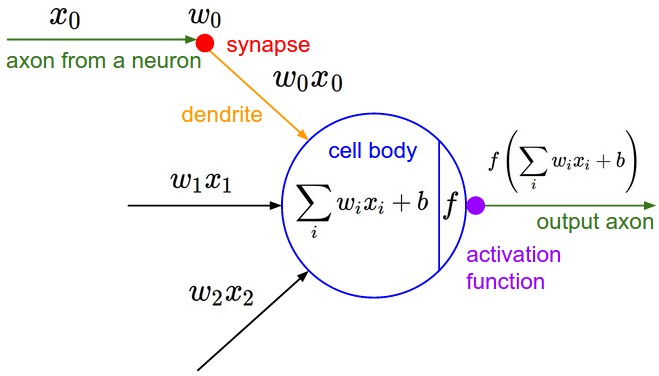

Example only contains one neuron - a neural network will have several connected neurons and a loss function

In [123]:
# inputs
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

# synaptic strengths (weights) of a neuron
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

# bias of neuron
b = Value(6.88, label='b')

x1w1 = x1 * w1; x1w1.label='x1*w1'
x2w2 = x2 * w2; x2w2.label='x2*w2'

x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1w1+x2w2'

n = x1w1x2w2 + b; n.label='n'
o = n.tanh(); o.label = 'o'
# tanh = hyperbolic function

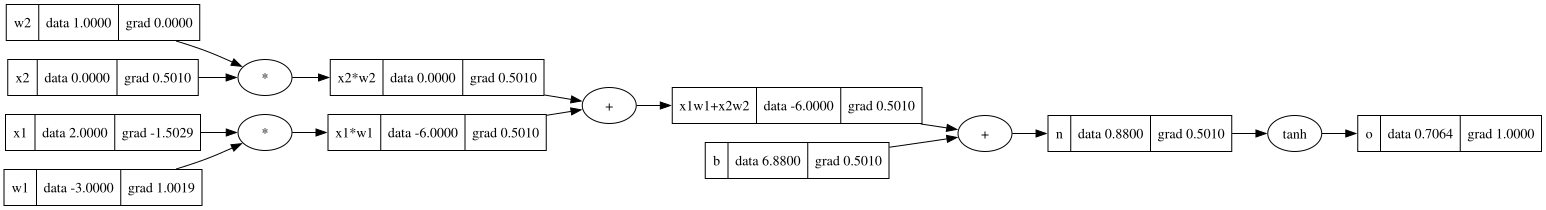

In [126]:
draw_dot(o)

In [ ]:
#1. To start backprop through tanh, what is local deriv of tanh?
# o = tanh(n)
# do/dn = 1 - o^2

#2. Plus operation distributes the gradient --> the local derivative of plus operation is 1, thus:
#   (x1w1 + x2w2).grad = 0.5 && b.grad = 0.5